In [46]:
# NIM : 2802392652
# NAMA: DANIEL SEBASTIAN WINATA
# HEART ATTACK DATA SET.CSV

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [47]:
df = pd.read_csv("Heart Attack Data Set.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [48]:
#pertama liat berapa banyak kolom dan baris
df.shape

(303, 14)

303 rows and 14 columns

In [49]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


all integers with one float

age = age   
sex = gender   
cp  = chest pain ( yes or no )    
trestbps = blood pressure   
chol = cholesterol   
fbs = blood sugar    
restecg = ECG test ( medical heart test )     
thalach = max heart rate    
exang = temporary chest pain, tightness, or discomfort caused by reduced blood flow to the heart muscle     
oldpeak = waveform abnormality seen on an Electrocardiogram (ECG/EKG)    
slope = the waveform slope     
ca = major vessels    
thal = thallasemia    
TARGET = HEART RATE RISK   

In [29]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [30]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [31]:
df["sex"].unique()

array([1, 0])

In [32]:
df["cp"].unique()

array([3, 2, 1, 0])

In [33]:
df["fbs"].unique()

array([1, 0])

In [34]:
df["restecg"].unique()

array([0, 1, 2])

In [35]:
df["exang"].unique()

array([0, 1])

In [36]:
df["slope"].unique()

array([0, 2, 1])

In [37]:
df["ca"].unique()

array([0, 2, 1, 3, 4])

In [38]:
df["thal"].unique()

array([1, 2, 3, 0])

In [50]:
df['target'].value_counts() # HEART ATTACK ATAU TIDAK

target
1    165
0    138
Name: count, dtype: int64

In [51]:
df[["sex","cp","fbs","restecg","exang","slope","ca","thal"]] = df[["sex","cp","fbs","restecg","exang","slope","ca","thal"]].astype(str)

In [52]:
numcols = ['age','trestbps','chol','thalach','oldpeak']
catcols = ["sex","cp","fbs","restecg","exang","slope","ca","thal"]
target = "target"

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    object 
 2   cp        303 non-null    object 
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    object 
 6   restecg   303 non-null    object 
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    object 
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    object 
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(1), int64(5), object(8)
memory usage: 33.3+ KB


target binary, maka logistic regression go to model option

In [54]:
X = df[numcols + catcols]   # features
y = df[target]              # label ( TARGET KITA CUY )

#split
Xtrain, Xtest, ytrain, ytest = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y ) #stratify = best practice

print(f"XTrain shape: {Xtrain.shape}")
print(f"XTest shape: {Xtest.shape}")

XTrain shape: (242, 13)
XTest shape: (61, 13)


In [55]:
# MISSING VALUES

# liat missing
missingXTRAIN = Xtrain.isna().sum()

print(missingXTRAIN)

# # impute pakai median
# for col in num_cols:
#     median_val = X_train[col].median()
#     X_train[col] = X_train[col].fillna(median_val)
#     X_test[col]  = X_test[col].fillna(median_val)

# # impute categorikal MISALNYA
# for col in cat_cols:
#     mode_val = X_train[col].mode()[0]
#     X_train[col] = X_train[col].fillna(mode_val)
#     X_test[col]  = X_test[col].fillna(mode_val)
    
# print("missing handled")

age         0
trestbps    0
chol        0
thalach     0
oldpeak     0
sex         0
cp          0
fbs         0
restecg     0
exang       0
slope       0
ca          0
thal        0
dtype: int64


bersih

gaada yang bisa di encode either

NEVERMIND ADA

In [56]:
# one hot encoder KARENA prevents the machine learning model from assuming an ordinal relationship! gaada urutan kok
# bentuk datanya tidak ordinal, gaada urutan (keparahan) maka pakai one hot encoder
# PAKAI COLUMN TRANSFORMER
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

In [57]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numcols),
        ('cat', categorical_transformer, catcols)
    ])

In [58]:
# Terapin ke data training
Xtrain_processed = preprocessor.fit_transform(Xtrain)

# Terapin ke data testing
Xtest_processed = preprocessor.transform(Xtest)

In [59]:
#Model
model = LogisticRegression(random_state=42, max_iter=1000)

#fit modelnya ( DI TRAIN )
model.fit(Xtrain_processed, ytrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Accuracy: 0.8688524590163934

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.82      0.85        28
           1       0.86      0.91      0.88        33

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



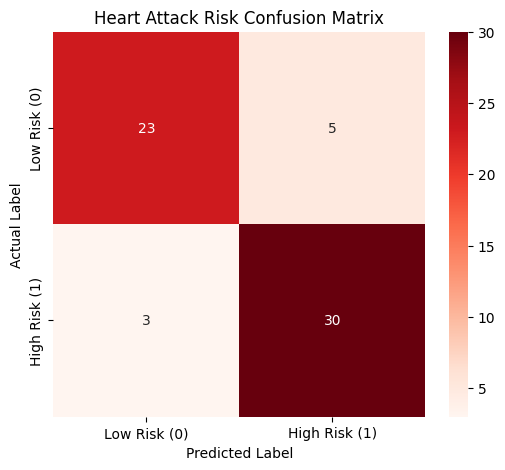

In [60]:
# waktunya mikin predictionsss
y_pred = model.predict(Xtest_processed)


print("Accuracy:", accuracy_score(ytest, y_pred))
print("\nClassification Report:\n", classification_report(ytest, y_pred))



# CONFUSION MATRIX
cm = confusion_matrix(ytest, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Low Risk (0)', 'High Risk (1)'], 
            yticklabels=['Low Risk (0)', 'High Risk (1)'])
plt.title('Heart Attack Risk Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()